# IMF Country Report → Dashboard: an LLM Text-to-Dashboard Pipeline (Ireland, 2026 Article IV)

**Module:** Data Science & AI — Assignment 1  |  **Student ID:** ____________  |  **Allocated report:** Ireland, 2025–2026
**Document analysed:** *IMF Country Report No. 26/156 — Ireland: 2026 Article IV Consultation, Staff Report* (June 2026), the latest Article IV report inside the allocated window.

### Pipeline architecture
```
PDF ─► pypdf extraction ─► cleaning (headers/footers/chart noise/line-merge) ─► section split
    ─► token-aware chunking (400 tok, 50 overlap, table-header carry) ─► DistilBERT embeddings ─► FAISS IndexFlatL2
    ├─► Task 1  summaries (<100 words / section) + executive summary  ──► LLM-as-a-Judge audit
    ├─► Task 2  theme counts · strengths/vulnerabilities · indicator JSON (RAG-grounded, fallbacks) ──► Judge audit vs human gold
    ├─► Task 3  RAG question answering + hallucination probe ──► Judge (faithfulness / completeness)
    ├─► Ext.    Multi-Query RAG vs single-query RAG
    └─► Task 4  tidy `pd.melt` long-format data ─► 4-panel dashboard (dpi=300)
```
**Design principles** (each maps to a marking-rubric line): fully automated top-to-bottom · every LLM call cached on disk (`outputs/llm_cache`) so re-runs cost nothing · no hard-coded local paths · API key only from Colab *Secrets* (`GEMINI_API_KEY`) or an environment variable · every numeric output is machine-checked against the source text (grounding check) and replaced by an explicit fallback if unsupported · null-safe plotting.

**How to run (Colab):** (1) add your Gemini key in the 🔑 *Secrets* panel as `GEMINI_API_KEY` and enable notebook access; (2) upload the PDF when asked (or place it next to the notebook); (3) *Runtime → Run all*. Outputs (`.json`, `.csv`, figures) land in `outputs/`.

## 0. Setup

In [22]:
# Install dependencies (Colab). Quiet; safe to re-run.
%pip install -q pypdf google-genai sentence-transformers faiss-cpu pandas matplotlib pydantic

In [ ]:
# Colab opened straight from GitHub contains only this .ipynb → fetch the repo (PDF + cached LLM responses)
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/gulldhudra/imf-ireland-llm-dashboard.git"
if "google.colab" in sys.modules and not Path("002-article-A001-en.pdf").exists():
    subprocess.run(["git", "clone", "-q", REPO_URL, "repo"], check=False)
    if Path("repo").exists():
        os.chdir("repo")
        print("Cloned repo → working in", os.getcwd())

In [23]:
import os, re, json, time, hashlib, math, difflib, random
from pathlib import Path
from typing import Optional, Literal
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pydantic import BaseModel

# ------------------------------------------------------------------ configuration
OUT_DIR   = Path("outputs")                 # every artefact is written here (relative path => portable)
CACHE_DIR = OUT_DIR / "llm_cache"           # on-disk cache of every LLM response
FIG_DIR   = OUT_DIR / "figures"
for d in (OUT_DIR, CACHE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

COUNTRY          = "Ireland"
REPORT_YEAR      = 2026                     # year of the Article IV report (first projection year in Table 1)
LAST_ACTUAL_YEAR = 2025                     # latest full-year outturn reported
PDF_FILENAME     = "002-article-A001-en.pdf"
PDF_URL          = "https://www.imf.org/-/media/files/publications/cr/2026/english/1irlea2026001.pdf"

EMBED_MODEL  = "sentence-transformers/multi-qa-distilbert-cos-v1"   # DistilBERT retrieval model, 512-token window
CHUNK_TOKENS, CHUNK_OVERLAP = 400, 50

# Model roles. The first model in each list that the API key can access is used (see resolve_model).
GEN_PREFS   = ["gemini-3.5-flash", "gemini-2.5-flash"]              # extraction + summarisation
ALT_PREFS   = ["gemini-3.5-flash-lite", "gemini-2.5-flash-lite"]    # cheaper comparison model (dashboard panel C)
JUDGE_PREFS = ["gemini-3.5-flash", "gemini-2.5-flash"]              # evaluator (different prompt + role than the generator)
MIN_INTERVAL = 4.0                          # seconds between *uncached* calls (free-tier rate limit)
TOP_K = 4                                   # chunks per retrieval query

random.seed(0); np.random.seed(0)

def save_json(obj, name):
    """Write a machine-readable result file into outputs/."""
    (OUT_DIR / name).write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str))

## 1. LLM client with disk cache, retries and schema-constrained output
* **Dual-LLM setup:** a *generator* role (extraction/summaries) and a separate *judge* role with its own adversarial system prompt.
* `call_llm` hashes (model, system prompt, prompt, schema) → JSON file. Re-running the notebook (or the marker running it) replays the cache, so no quota is burnt and results are reproducible.
* Structured outputs use Gemini `response_schema` with Pydantic models → strictly valid JSON by construction; a repair path handles the rare malformed reply.

In [24]:
def get_api_key():
    """Colab Secrets first, then environment variable. The key is never printed or stored."""
    try:
        from google.colab import userdata
        k = userdata.get("GEMINI_API_KEY")
        if k: return k
    except ImportError:
        pass                                           # not running in Colab → try environment variable
    except Exception as e:                             # Colab-specific: secret missing / access not granted
        print(f"Colab Secrets problem: {type(e).__name__}: {e}")
        print("→ In the 🔑 Secrets panel: name must be exactly GEMINI_API_KEY, 'Notebook access' toggle ON, value pasted.")
    return os.environ.get("GEMINI_API_KEY")

client, types = None, None
_key = get_api_key()
if not _key and len(list(CACHE_DIR.glob("*.json"))) >= 60:
    print("ℹ️ No API key, but a complete LLM cache is present → running in cache-replay mode (no API calls).")
elif not _key:
    # VS Code / local Jupyter: no secret store → hidden prompt (nothing is echoed, printed or written to disk).
    # Press Enter with an empty box to run in cache-replay mode (needs a populated outputs/llm_cache).
    import getpass
    try:
        _key = getpass.getpass("Paste your GEMINI_API_KEY (hidden, not saved; Enter = cache-replay only): ").strip() or None
    except Exception:
        _key = None
if _key:
    try:
        from google import genai
        from google.genai import types
        client = genai.Client(api_key=_key)
    except Exception as e:
        print("Could not create Gemini client:", e)
else:
    print("⚠️ No GEMINI_API_KEY found – the notebook will run only from cached LLM responses (outputs/llm_cache).")

LLM_LOG = []   # (tag, model_actually_used, latency_s, cached)

class DailyQuotaExceeded(Exception):
    """Free-tier per-day request cap hit for one model."""

# Fallback pool: if the requested model's DAILY quota is exhausted (free tier = ~20 requests/day/model) or the model
# does not exist for this key, the call is transparently served by the next model. Every response is cached under the
# *requested* key, and the model that really answered is stored in the record (see run_manifest.json).
EXTRA_FALLBACKS = ["gemini-2.5-flash", "gemini-2.5-flash-lite", "gemini-2.0-flash"]
EXHAUSTED = set()

def _generate(prompt, system, model, schema, temperature):
    cfg = dict(temperature=temperature)
    if system: cfg["system_instruction"] = system
    if schema: cfg.update(response_mime_type="application/json", response_schema=schema)
    last_err = None
    for attempt in range(6):
        try:
            t0 = time.time()
            resp = client.models.generate_content(model=model, contents=prompt, config=types.GenerateContentConfig(**cfg))
            return dict(text=resp.text or "", latency_s=round(time.time() - t0, 2), model=model)
        except Exception as e:
            last_err = e; msg = str(e).lower()
            if "per day" in msg or "perday" in msg or "limit: 0" in msg:
                raise DailyQuotaExceeded(model)                       # retrying cannot help → fail fast
            if "404" in msg or "not found" in msg or "permission" in msg:
                raise LookupError(f"{model}: {str(e)[:80]}")
            m = re.search(r"retry in ([\d.]+)s", msg)                 # per-minute limit → honour the server's delay
            time.sleep(min(70, float(m.group(1)) + 1) if m else min(60, 5 * 2 ** attempt))
    raise RuntimeError(f"LLM call failed after retries: {last_err}")

def call_llm(prompt, *, system=None, model, schema=None, tag="", temperature=0.0):
    """Cached, retried Gemini call with model fallback. Returns dict(text, latency_s, model, cached)."""
    sig = json.dumps([model, system, prompt, schema.__name__ if schema else None, temperature], sort_keys=True)
    path = CACHE_DIR / (hashlib.sha256(sig.encode()).hexdigest()[:32] + ".json")
    if path.exists():
        rec = json.loads(path.read_text()); rec["cached"] = True
        LLM_LOG.append((tag, rec["model"], rec["latency_s"], True)); return rec
    if client is None:
        raise RuntimeError(f"No cached response for [{tag}] and no API key set. Add GEMINI_API_KEY in Colab Secrets.")
    pool = [model] + [m for m in dict.fromkeys(GEN_PREFS + ALT_PREFS + JUDGE_PREFS + EXTRA_FALLBACKS) if m != model]
    for cand in pool:
        if cand in EXHAUSTED: continue
        try:
            rec = _generate(prompt, system, cand, schema, temperature)
        except DailyQuotaExceeded:
            EXHAUSTED.add(cand); print(f"   ⚠️ daily free quota exhausted for {cand} → trying next model"); continue
        except LookupError:
            EXHAUSTED.add(cand); continue
        rec["tag"] = tag; path.write_text(json.dumps(rec)); rec["cached"] = False
        LLM_LOG.append((tag, rec["model"], rec["latency_s"], False))
        time.sleep(MIN_INTERVAL)
        return rec
    raise RuntimeError("All candidate models hit their free-tier DAILY quota. Progress is saved in outputs/llm_cache — "
                       "re-run this cell tomorrow (quota resets daily) or enable billing on the API key's project.")

def llm_text(prompt, **kw):
    return call_llm(prompt, **kw)["text"].strip()

def llm_json(prompt, *, schema, **kw):
    """Schema-constrained call → validated dict. One repair attempt, then raises."""
    rec = call_llm(prompt, schema=schema, **kw)
    txt = re.sub(r"^```(?:json)?|```$", "", rec["text"].strip(), flags=re.M).strip()
    try:
        return schema.model_validate_json(txt).model_dump(), rec
    except Exception:
        fixed = llm_text("Return ONLY the corrected, valid JSON for this schema; no commentary:\n" + txt,
                         model=kw["model"], tag=kw.get("tag", "") + "-repair")
        fixed = re.sub(r"^```(?:json)?|```$", "", fixed, flags=re.M).strip()
        return schema.model_validate_json(fixed).model_dump(), rec

def resolve_model(prefs, role):
    """Pick the first model id the key can use (model names change between API releases)."""
    for m in prefs:
        try:
            rec = call_llm("Reply with the single word OK.", model=m, tag=f"probe-{role}")
            print(f"{role:>6}: {rec['model']}"); return rec["model"]
        except Exception as e:
            print(f"{role:>6}: {m} unavailable ({str(e)[:60]}…)")
    raise RuntimeError(f"No usable model for role '{role}' from {prefs}")

GEN_MODEL   = resolve_model(GEN_PREFS,   "GEN")
ALT_MODEL   = resolve_model(ALT_PREFS,   "ALT")
JUDGE_MODEL = resolve_model(JUDGE_PREFS, "JUDGE")

   GEN: gemini-3.5-flash
   ALT: gemini-3.5-flash-lite
 JUDGE: gemini-3.5-flash


## 2. Task 1 — PDF ingestion, cleaning and section segmentation
**Why these cleaning rules?** `pypdf` returns the printed page header ("IRELAND / 19 INTERNATIONAL MONETARY FUND"), the copyright footer, chart source lines and — worst — every chart's axis tick labels as stand-alone numeric lines. These pollute embeddings and theme counts, so they are removed on *narrative* pages. **Table pages are the opposite case**: line structure carries meaning (label + year columns), so they are kept line-by-line and only header/footer noise is dropped. Paragraph lines are re-joined (de-hyphenated, and joined across page breaks when a sentence continues).

In [25]:
from pypdf import PdfReader

def locate_pdf():
    """Find the report PDF: local folder → Colab upload → download from imf.org."""
    for p in [Path(PDF_FILENAME), Path("data") / PDF_FILENAME, Path("/content") / PDF_FILENAME]:
        if p.exists(): return p
    pdfs = [p for p in Path(".").glob("*.pdf") if "allocation" not in p.name.lower()]
    if len(pdfs) == 1: return pdfs[0]
    try:                                                       # Colab: interactive upload
        from google.colab import files
        print("Upload the IMF Ireland report PDF …")
        up = files.upload(); name = next(iter(up)); return Path(name)
    except Exception:
        pass
    import urllib.request
    print("Downloading from imf.org …")
    dest = Path(PDF_FILENAME); urllib.request.urlretrieve(PDF_URL, dest); return dest

PDF_PATH = locate_pdf()
reader = PdfReader(str(PDF_PATH))
RAW_PAGES = [p.extract_text() or "" for p in reader.pages]
print(f"{PDF_PATH.name}: {len(RAW_PAGES)} pages, {sum(len(p.split()) for p in RAW_PAGES):,} raw words")

002-article-A001-en.pdf: 49 pages, 20,540 raw words


In [26]:
NOISE_LINE = [re.compile(p) for p in (
    r"^IRELAND\s*$", r"^\d+\s+INTERNATIONAL MONETARY FUND\s*$", r"^INTERNATIONAL MONETARY FUND\s+\d+\s*$",
    r"^©\s*International Monetary Fund.*$", r"^Sources?:.*$")]
CHART_AXIS = re.compile(r"^(?:[-–−]?\d[\d.,]*|\d{4}(?:Q[1-4])?)(?:\s+(?:[-–−]?\d[\d.,]*|\d{4}(?:Q[1-4])?))*$")
PRINTED_PAGE = re.compile(r"(\d+)\s+INTERNATIONAL MONETARY FUND|INTERNATIONAL MONETARY FUND\s+(\d+)")

def _head(pattern, fmt):
    return re.compile(pattern), fmt

HEADINGS = [   # (regex, section-name builder). Section names double as chapter titles for Task 1.
    _head(r"^(CONTEXT|RECENT DEVELOPMENTS|OUTLOOK AND RISKS|POLICY DISCUSSIONS|STAFF APPRAISAL)\s*$", lambda m: m.group(1)),
    _head(r"^([A-C])\.\s+(Fiscal Policy|Financial and Macroprudential Policies|Structural Policy)\s*$", lambda m: f"{m.group(1)}. {m.group(2)}"),
    _head(r"^Table 1\.\s+\w+:\s+Selected Economic Indicators", lambda m: "STATISTICAL TABLES"),
    _head(r"^(Annex [IVX]+)\.\s+(?!Figure|Table)(?!.*(?:continued|concluded))(.{5,90}?)\s*$",
          lambda m: f"{m.group(1)}. " + re.sub(r"(?<=[a-z])\d$", "", m.group(2))),
]
def section_heading(line):
    for rx, fmt in HEADINGS:
        m = rx.match(line.strip())
        if m: return fmt(m)
    return None

def is_table_page(raw):
    return bool(re.search(r"^Table \d+\.", raw, re.M) or re.search(r"^Annex VI\. Table", raw, re.M))

def clean_document(raw_pages):
    """Return a list of paragraph dicts {text, kind, page, printed, section} in reading order."""
    paras, section = [], "FRONT MATTER"
    for pdf_i, raw in enumerate(raw_pages, start=1):
        m = PRINTED_PAGE.search(raw); printed = int(m.group(1) or m.group(2)) if m else pdf_i
        table_mode = is_table_page(raw)
        cur = ""
        def flush():
            nonlocal cur
            if cur.strip(): paras.append(dict(text=cur.strip(), kind="text", page=pdf_i, printed=printed, section=section))
            cur = ""
        for line in raw.splitlines():
            s = line.strip()
            if not s or any(rx.match(s) for rx in NOISE_LINE): continue
            if not table_mode and CHART_AXIS.match(s): continue            # chart tick labels
            h = section_heading(s)
            if h:
                flush(); section = h
                if not s.startswith("Table 1"): continue                    # keep table title line as data
            if table_mode:
                paras.append(dict(text=s, kind="tableline", page=pdf_i, printed=printed, section=section)); continue
            starts_new = (re.match(r"^\d{1,2}\.\s+\S", s) or
                          (cur and re.search(r"[.:;?!]$", cur) and re.match(r"^(\d{1,2}\s+[A-Z]|[•▪]\s|Figure \d|Authorities|Staff )", s)))
            if starts_new: flush()
            if cur.endswith("-") and len(cur) > 1 and cur[-2].isalpha(): cur += s          # de-hyphenate
            else: cur = (cur + " " + s).strip()
        flush()
    # stitch sentences broken by a page boundary
    stitched = []
    for p in paras:
        if (stitched and p["kind"] == "text" and stitched[-1]["kind"] == "text" and p["page"] != stitched[-1]["page"]
                and p["section"] == stitched[-1]["section"]
                and not re.search(r"[.:;?!]$", stitched[-1]["text"]) and p["text"][:1].islower()):
            stitched[-1]["text"] += " " + p["text"]
        else:
            stitched.append(p)
    return stitched

PARAS = clean_document(RAW_PAGES)

def build_sections(paras):
    secs = {}
    for p in paras:
        s = secs.setdefault(p["section"], dict(paras=[], pages=[]))
        s["paras"].append(p); s["pages"].append(p["printed"])
    for name, s in secs.items():
        s["text"] = "\n".join(p["text"] if p["kind"] == "tableline" else "\n" + p["text"] for p in s["paras"]).strip()
        s["narrative"] = "\n\n".join(p["text"] for p in s["paras"] if p["kind"] == "text")
        s["words"] = len(s["text"].split()); s["page_range"] = (min(s["pages"]), max(s["pages"]))
    return secs

SECTIONS = build_sections(PARAS)
FULL_TEXT = "\n\n".join(f"### {n}\n{s['text']}" for n, s in SECTIONS.items() if n != "FRONT MATTER")
NARRATIVE_WORDS = sum(len(s["narrative"].split()) for s in SECTIONS.values())
print(f"{'section':55s} {'pages':>9s} {'words':>6s}")
for n, s in SECTIONS.items():
    print(f"{n[:55]:55s} {s['page_range'][0]:>4}-{s['page_range'][1]:<4} {s['words']:>6}")
print("clean words:", sum(s['words'] for s in SECTIONS.values()), "| narrative words:", NARRATIVE_WORDS)

section                                                     pages  words
CONTEXT                                                    4-4       302
RECENT DEVELOPMENTS                                        5-10     1591
OUTLOOK AND RISKS                                         10-12      848
A. Fiscal Policy                                          12-17     2207
B. Financial and Macroprudential Policies                 18-22     1738
C. Structural Policy                                      22-25     1447
STAFF APPRAISAL                                           25-27      818
STATISTICAL TABLES                                        28-32     2063
Annex I. GDP and Exports Growth in 2025                   33-34     1127
Annex II. Implementation of Past IMF Recommendations      36-36      444
Annex III. Risk Assessment Matrix                         37-39     1065
Annex IV. External Sector Assessment                      40-41      992
Annex V. Sovereign Risk and Debt Sustainability Fra

## 3. Task 1 — Token-aware chunking and Task 3 — vector index
* Chunks are **sentence-aligned**, ≤ 400 tokens (counted with the *same* DistilBERT tokenizer as the embedding model, so the chunk size is exactly what the encoder sees) with ≥ 50 tokens of overlap carried from the previous chunk.
* **Table-header carry:** when a table chunk starts mid-table, the table title and year header are prepended, otherwise a row such as `Inflation (HICP) 8.1 5.2 …` would be separated from its `2022 … 2031` column labels and could not be interpreted.
* Dense embeddings are L2-normalised so Euclidean distance in `IndexFlatL2` is monotonic with cosine similarity. Embeddings are cached on disk.

In [27]:
from sentence_transformers import SentenceTransformer
import faiss

embedder = SentenceTransformer(EMBED_MODEL)
tok = embedder.tokenizer
def n_tokens(text):
    return len(tok.encode(text, add_special_tokens=False, truncation=False))

TABLE_TITLE = re.compile(r"^Table \d+\.")
YEAR_LINE   = re.compile(r"^(?:\d{4}\s+){2,}\d{4}\s*$")
SENT_SPLIT  = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9(“\"])")

def make_units(paras_of_section):
    """Split paragraphs into sentence/line units; track the active table header for table lines."""
    units, title, years = [], None, None
    for p in paras_of_section:
        if p["kind"] == "tableline":
            if TABLE_TITLE.match(p["text"]): title, years = p["text"], None
            elif YEAR_LINE.match(p["text"]): years = p["text"]
            hdr = (title + ("\n" + years if years else "")) if title else None
            parts = [p["text"]]
        else:
            hdr, parts = None, SENT_SPLIT.split(p["text"])
        for t in parts:
            units.append(dict(text=t, kind=p["kind"], page=p["printed"], hdr=hdr, ntok=n_tokens(t)))
    return units

def chunk_section(name, units, max_tokens=CHUNK_TOKENS, overlap=CHUNK_OVERLAP):
    chunks, cur, cur_tok = [], [], 0
    def emit():
        if not cur: return
        text = ""
        for i, u in enumerate(cur):
            text += (u["text"] if i == 0 else (("\n" if "tableline" in (u["kind"], cur[i-1]["kind"]) else " ") + u["text"]))
        hdr = cur[0]["hdr"]
        if hdr and cur[0]["kind"] == "tableline" and not text.startswith(hdr.split("\n")[0]):
            text = hdr + "\n" + text                                   # table-header carry
        chunks.append(dict(section=name, text=text, pages=sorted({u["page"] for u in cur}), n_tokens=n_tokens(text)))
    for u in units:
        if u["ntok"] > max_tokens:                                      # pathological long unit → split on words
            words = u["text"].split(); step = max(1, int(len(words) * max_tokens / u["ntok"]) - 5)
            pieces = [dict(u, text=" ".join(words[i:i + step]), ntok=n_tokens(" ".join(words[i:i + step])))
                      for i in range(0, len(words), step)]
        else:
            pieces = [u]
        for pu in pieces:
            if cur and cur_tok + pu["ntok"] > max_tokens:
                emit()
                carry, ct = [], 0
                for back in reversed(cur):                              # sentence-aligned overlap ≥ `overlap` tokens
                    carry.insert(0, back); ct += back["ntok"]
                    if ct >= overlap: break
                cur, cur_tok = (carry, ct) if ct + pu["ntok"] <= max_tokens else ([], 0)
            cur.append(pu); cur_tok += pu["ntok"]
    emit()
    return chunks

CHUNKS = []
for name, s in SECTIONS.items():
    if name == "FRONT MATTER": continue
    CHUNKS += chunk_section(name, make_units(s["paras"]))
for i, c in enumerate(CHUNKS): c["id"] = i
tok_counts = np.array([c["n_tokens"] for c in CHUNKS])
print(f"{len(CHUNKS)} chunks | tokens min/median/max = {tok_counts.min()}/{int(np.median(tok_counts))}/{tok_counts.max()}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

95 chunks | tokens min/median/max = 72/380/437


In [28]:
def build_index(chunks):
    """Embed chunks (cached on disk) and build a FAISS IndexFlatL2."""
    sig = hashlib.sha256((EMBED_MODEL + "||".join(c["text"] for c in chunks)).encode()).hexdigest()[:16]
    npy = CACHE_DIR / f"emb_{sig}.npy"
    if npy.exists():
        emb = np.load(npy)
    else:
        emb = embedder.encode([c["text"] for c in chunks], batch_size=32, normalize_embeddings=True,
                              show_progress_bar=False).astype("float32")
        np.save(npy, emb)
    idx = faiss.IndexFlatL2(emb.shape[1]); idx.add(emb)
    return idx, emb

INDEX, EMB = build_index(CHUNKS)

def retrieve(query, k=TOP_K):
    """Dense retrieval: returns top-k chunks with cosine similarity (1 - L2²/2 for unit vectors)."""
    q = embedder.encode([query], normalize_embeddings=True).astype("float32")
    D, I = INDEX.search(q, k)
    return [dict(CHUNKS[i], score=float(1 - d / 2)) for d, i in zip(D[0], I[0]) if i >= 0]

print("index vectors:", INDEX.ntotal, "dim:", EMB.shape[1])
for r in retrieve("countercyclical capital buffer rate", 2):
    print(f"  sim={r['score']:.3f} [{r['section']}] p.{r['pages']} :: {r['text'][:100]!r}")

index vectors: 95 dim: 768
  sim=0.414 [B. Financial and Macroprudential Policies] p.[20] :: 'Macroprudential policy settings remain appropriate. The CCyB rate is maintained at 1.5 percent, a le'
  sim=0.319 [Annex V. Sovereign Risk and Debt Sustainability Framework] p.[45] :: 'Real growth rate -4.2 0.3 -1.2 -0.8 -0.7 -0.6 -0.6 0.4 0.4 0.5 0.5… Real exchange rate 0.0 … … … … …'


## 4. Task 1 — Summarisation with an LLM-as-a-Judge audit
**Prompt design (and why).**
* *System directive* fixes role, audience and the three rules that matter for an IMF text: (1) use only the supplied text, (2) copy numbers/units/years verbatim, (3) hard length limit. Putting them in `system_instruction` (not the user turn) keeps them from being diluted by long section text.
* *User prompt* states the length limit **again** with a target range (70–90 words) — LLMs overshoot a bare "under 100 words". Python then **verifies** the limit and triggers one repair call if violated.
* A deliberately naive **v1 prompt** ("Summarise this text.") is run on three sections as a baseline, so the effect of prompt optimisation is *measured*, not assumed (`outputs/prompt_ab.json`).

**Judge design.** The evaluator is a separate role with an adversarial system prompt, sees the *source text* plus the output, and returns Pydantic-validated 1–5 scores for **consistency**, **completeness**, **factual alignment** plus a verbatim list of unsupported claims. Rubric anchors are spelled out to reduce score inflation; the judge is told that length is not quality.

In [29]:
SYSTEM_SUMMARISER = """You are a senior financial-stability analyst summarising IMF Article IV staff reports for a central-bank audience.
Rules:
1. Use ONLY facts stated in the supplied text. Never add outside knowledge, causes, forecasts or numbers.
2. Copy every number, unit, year and institution name exactly as written (e.g. '1.5 percent', 'CCyB', 'GNI*').
3. Formal, neutral tone. No filler such as 'the report discusses'. Obey the requested length strictly."""

SYSTEM_JUDGE = """You are a sceptical independent auditor of AI-generated summaries and data extractions of IMF documents.
You receive SOURCE text and an OUTPUT. Score the OUTPUT only against the SOURCE (never against your own knowledge).
Scale (integers 1-5): 5 = no defect; 4 = minor wording issue; 3 = one material gap/error; 2 = several; 1 = mostly wrong.
 - consistency: no internal contradictions; numbers, signs, units and years agree with each other and the SOURCE.
 - completeness: the main findings, key figures and the staff recommendation/risk judgement of the SOURCE are covered.
 - factual_alignment: every claim and number is supported by the SOURCE. Any invented/altered number caps this at 2.
List each unsupported or altered claim verbatim in unsupported_claims (empty list if none). Length is NOT quality. Be strict."""

class JudgeScore(BaseModel):
    consistency: int
    completeness: int
    factual_alignment: int
    unsupported_claims: list[str]
    rationale: str

def judge_output(output, source, what, tag):
    prompt = (f"TASK THAT PRODUCED THE OUTPUT: {what}\n\nSOURCE:\n<<<\n{source}\n>>>\n\nOUTPUT TO AUDIT:\n<<<\n{output}\n>>>\n\n"
              "Return the JSON audit.")
    scores, rec = llm_json(prompt, schema=JudgeScore, system=SYSTEM_JUDGE, model=JUDGE_MODEL, tag=tag)
    for k in ("consistency", "completeness", "factual_alignment"):
        scores[k] = int(min(5, max(1, scores[k])))
    return scores

def word_count(t): return len(re.findall(r"\b[\w'’%*.-]+\b", t))

def summarise_section(name, text, model=None, optimised=True):
    """Return dict(summary, words, within_limit, repaired, latency_s)."""
    model = model or GEN_MODEL
    if optimised:
        prompt = (f"Summarise the section '{name}' of the {COUNTRY} staff report below in FEWER THAN 100 words "
                  "(target 70-90), as ONE paragraph. Cover, in this order: the main finding, the key figures, and the IMF staff "
                  f"recommendation or risk judgement.\n\nSECTION TEXT:\n<<<\n{text}\n>>>")
        kw = dict(system=SYSTEM_SUMMARISER)
    else:                                                  # naive baseline prompt for the A/B test
        prompt, kw = f"Summarise the following text.\n\n{text}", {}
    rec = call_llm(prompt, model=model, tag=f"sum-{'v2' if optimised else 'v1'}-{name[:20]}", **kw)
    out, repaired = rec["text"].strip(), False
    if optimised and word_count(out) >= 100:               # programmatic constraint check + one repair attempt
        out = llm_text(f"Shorten this to 80 words or fewer. Keep all numbers exactly. Output the paragraph only.\n\n{out}",
                       model=model, system=SYSTEM_SUMMARISER, tag=f"sum-repair-{name[:20]}"); repaired = True
    return dict(summary=out, words=word_count(out), within_limit=word_count(out) < 100,
                repaired=repaired, latency_s=rec["latency_s"])

SUMMARY_SECTIONS = [n for n, s in SECTIONS.items() if n != "FRONT MATTER" and s["words"] >= 120]
SECTION_SUMMARIES = {}
for n in SUMMARY_SECTIONS:
    r = summarise_section(n, SECTIONS[n]["text"])
    r["judge"] = judge_output(r["summary"], SECTIONS[n]["text"], f"Summarise section '{n}' in <100 words", f"judge-sum-{n[:20]}")
    r["pages"] = SECTIONS[n]["page_range"]
    SECTION_SUMMARIES[n] = r
J3 = ("consistency", "completeness", "factual_alignment")
sum_df = pd.DataFrame({n: {"words": r["words"], "ok(<100)": r["within_limit"], **{k: r["judge"][k] for k in J3}}
                       for n, r in SECTION_SUMMARIES.items()}).T
display(sum_df) if "display" in globals() else print(sum_df)
print("Constraint adherence:", f"{sum_df['ok(<100)'].astype(float).mean():.0%}", "| mean judge scores:", sum_df[list(J3)].astype(float).mean().round(2).to_dict())

                                                   words ok(<100) consistency  \
CONTEXT                                               88     True           5   
RECENT DEVELOPMENTS                                   94     True           5   
OUTLOOK AND RISKS                                     91     True           5   
A. Fiscal Policy                                      98     True           5   
B. Financial and Macroprudential Policies             96     True           5   
C. Structural Policy                                  89     True           5   
STAFF APPRAISAL                                       90     True           5   
STATISTICAL TABLES                                    95     True           5   
Annex I. GDP and Exports Growth in 2025               91     True           5   
Annex II. Implementation of Past IMF Recommenda...    90     True           5   
Annex III. Risk Assessment Matrix                     89     True           5   
Annex IV. External Sector As

### 4b. Prompt A/B test — naive v1 vs optimised v2 (3 sections)
Measured outcomes: word-limit adherence and judge scores. Results feed the report's "prompt quality / failure modes" discussion.

In [30]:
AB_SECTIONS = [n for n in ("RECENT DEVELOPMENTS", "B. Financial and Macroprudential Policies", "STAFF APPRAISAL") if n in SECTIONS]
prompt_ab = []
for n in AB_SECTIONS:
    for version, opt in (("v1_naive", False), ("v2_optimised", True)):
        r = summarise_section(n, SECTIONS[n]["text"], optimised=opt)
        j = judge_output(r["summary"], SECTIONS[n]["text"], f"Summarise section '{n}' in <100 words", f"judge-ab-{version}-{n[:15]}")
        prompt_ab.append(dict(section=n, version=version, words=r["words"], within_limit=r["within_limit"], **j))
ab_df = pd.DataFrame(prompt_ab)
save_json(prompt_ab, "prompt_ab.json")
print(ab_df.groupby("version")[["words", "within_limit", "consistency", "completeness", "factual_alignment"]].mean().round(2))

               words  within_limit  consistency  completeness  \
version                                                         
v1_naive      327.67           0.0          5.0          5.00   
v2_optimised   93.33           1.0          5.0          4.33   

              factual_alignment  
version                          
v1_naive                    4.0  
v2_optimised                5.0  


### 4c. Executive summary of the *complete* report
Map-reduce: the per-section summaries (map) plus the full *Staff Appraisal* (the IMF's own conclusions) are the input to one reduce call. The judge audits the bullets against the **entire cleaned report**, not against the summaries (so errors cannot hide behind an earlier summarisation step).

In [31]:
def executive_summary():
    digest = "\n".join(f"[{n}] {r['summary']}" for n, r in SECTION_SUMMARIES.items())
    appraisal = SECTIONS.get("STAFF APPRAISAL", {}).get("narrative", "")
    prompt = (f"Write the EXECUTIVE SUMMARY of the {COUNTRY} {REPORT_YEAR} Article IV staff report as 6-8 bullet points, each starting with '- ' "
              "and at most 35 words. Focus on financial-stability findings and risk assessments: banks (capital, asset quality, profitability), "
              "macro-financial outlook, credit/housing, fiscal and sovereign position, non-bank/external/systemic risks, and the main IMF "
              "recommendations. Keep every number exactly as in the source.\n\n"
              f"SECTION SUMMARIES:\n{digest}\n\nSTAFF APPRAISAL (full text):\n<<<\n{appraisal}\n>>>")
    text = llm_text(prompt, system=SYSTEM_SUMMARISER, model=GEN_MODEL, tag="exec-summary")
    bullets = [re.sub(r"^[-•*]\s*", "", l).strip() for l in text.splitlines() if l.strip().startswith(("-", "•", "*"))]
    judge = judge_output("\n".join("- " + b for b in bullets), FULL_TEXT, "Executive summary (6-8 bullets) of the full report", "judge-exec")
    return dict(bullets=bullets, max_bullet_words=max(word_count(b) for b in bullets), n_bullets=len(bullets), judge=judge)

EXEC = executive_summary()
for b in EXEC["bullets"]: print("•", b)
print(EXEC["n_bullets"], "bullets | longest:", EXEC["max_bullet_words"], "words | judge:", {k: EXEC["judge"][k] for k in ("consistency", "completeness", "factual_alignment")})
save_json(dict(executive_summary=EXEC, sections=SECTION_SUMMARIES), "summaries.json")

• Modified domestic demand growth is projected to moderate from almost 5 percent in 2025 to about 2½ percent in 2026–27, while headline inflation rises to 3½ percent in 2026.
• The banking sector remains resilient, with Stage 3 and stage 2 loans declining to 1.4 and 7.7 percent in 2025Q4, and NPL ratios dropping to 1.5 percent in 2025.
• Non-bank financial sector assets exceeded €7 trillion in 2025 (over 20 times estimated GNI*), where vulnerabilities from leverage and liquidity mismatches risk amplifying adverse shocks.
• The CCyB rate is maintained at 1.5 percent, while staff advises the CBI to adjust macroprudential settings as warranted and lead the development of an NBFI macroprudential framework.
• Ireland is assessed at low risk of sovereign stress, with public debt projected to decline to about 26 percent of GDP (about 50 percent of GNI*) in 2031.
• The external position is preliminarily assessed to be moderately stronger than fundamentals, with the current account surplus decl

## 5. Task 2 — Thematic distribution over the 7 financial-stability themes
**Method.** A transparent, auditable *lexicon* approach: each theme is a regex alternation of domain terms. Matches are counted on **narrative prose only** (table rows excluded — they would inflate counts via row labels such as "Inflation (HICP)"). Within a theme a text span can match once; across themes a span may count towards two themes (e.g. "mortgage lending") — documented, intentional, and the reason the result is read as *relative density*, not a partition.
We report (a) raw occurrences, (b) density per 1,000 narrative words (comparable across sections) and (c) the number of chunks in which the theme appears (breadth of coverage). The lexicon is a limitation (no semantics) — discussed in the report.

In [32]:
THEMES = {
 "Inflation & Prices": r"inflation\w*|\bHICP\b|\bCPI\b|disinflation\w*|price pressures?|GDP deflator|cost[- ]of[- ]living|price stability|energy prices?",
 "Interest Rates & Credit": r"interest rates?|policy rates?|\bECB\b|monetary policy|\bcredit\b|\blending\b|\bloans?\b|\bborrow\w*|\byields?\b|\bspreads?\b|rate (?:cuts?|hikes?|increases?)",
 "Housing & Real Estate": r"\bhous(?:ing|es?|ehold formation)\b|house prices?|property|real estate|\bCRE\b|\brents?\b|\brental\b|dwellings?|residential|\bmortgage\w*|homeowner\w*|construction",
 "Banking Capital & Liquidity": r"\bbank(?:s|ing)?\b|capital (?:buffers?|ratios?|requirements?|positions?|adequacy|cushions?)|\bCCyB\b|\bCET1\b|\bCT1\b|tier 1|liquidity|\bBasel\b|stress tests?|profitab\w+|\bNPLs?\b|non-performing|asset quality|\bdeposits?\b|leverage ratio",
 "Sovereign Debt": r"(?:public|government|sovereign|gross|net|external) debt|\bsovereign\b|\bdebt\b|debt sustainability|fiscal (?:rules?|framework|space|balance|surplus|deficit|stance|buffers?|risks?|policy)|\bbonds?\b|credit rating|\bMTFSP\b|primary balance|public finances?",
 "Labor Market Dynamics": r"\blabou?r\b|employment|unemployment|\bwages?\b|\bworkers?\b|\bjobs?\b|vacanc\w+|participation rate|skills? (?:shortages?|mismatch\w*)|immigration|workforce|\bhiring\b",
 "Systemic Financial Risk": r"systemic|financial stability|contagion|spillovers?|vulnerabilit\w+|\bshocks?\b|risk assessment|\bNBFIs?\b|non-bank|investment funds?|interconnected\w*|tail risks?|macroprudential|leveraged finance|cyber\w*|financial sector|geopolitical",
}
THEME_RX = {k: re.compile(v, re.I) for k, v in THEMES.items()}

def theme_scan():
    rows, per_section = {}, {}
    for t, rx in THEME_RX.items():
        per_section[t] = {n: len(rx.findall(s["narrative"])) for n, s in SECTIONS.items() if n != "FRONT MATTER"}
    total_words = NARRATIVE_WORDS
    counts = {t: sum(v.values()) for t, v in per_section.items()}
    density = {t: round(1000 * c / total_words, 2) for t, c in counts.items()}
    chunk_cov = {t: sum(bool(THEME_RX[t].search(c["text"])) for c in CHUNKS) for t in THEMES}
    top_terms = {}
    for t, rx in THEME_RX.items():
        from collections import Counter
        top_terms[t] = Counter(m.group(0).lower() for s in SECTIONS.values() for m in rx.finditer(s["narrative"])).most_common(5)
    return dict(counts=counts, density_per_1000_words=density, chunks_with_theme=chunk_cov, n_chunks=len(CHUNKS),
                narrative_words=total_words, per_section=per_section, top_terms=top_terms)

THEME_RESULT = theme_scan()
save_json(THEME_RESULT, "thematic_counts.json")
theme_df = pd.DataFrame({"occurrences": THEME_RESULT["counts"], "per_1000_words": THEME_RESULT["density_per_1000_words"],
                         "chunks_with_theme": THEME_RESULT["chunks_with_theme"]}).sort_values("per_1000_words", ascending=False)
print(theme_df)

                             occurrences  per_1000_words  chunks_with_theme
Sovereign Debt                       154           10.11                 49
Housing & Real Estate                112            7.35                 40
Systemic Financial Risk              110            7.22                 39
Banking Capital & Liquidity          104            6.83                 36
Interest Rates & Credit               68            4.46                 27
Labor Market Dynamics                 66            4.33                 25
Inflation & Prices                    47            3.09                 24


## 6. Task 2 — Qualitative risk insights (strengths vs. vulnerabilities)
The LLM must return ≤ 7 growth drivers/strengths and ≤ 7 vulnerabilities, each with a **verbatim evidence quote**. Python then (i) checks that every quote really occurs in the report (exact or ≥ 85 % fuzzy match) and (ii) records the page it came from. Items whose quote cannot be found are flagged `quote_verified=false` rather than silently trusted — this is the guard against hallucinated "insights".

In [33]:
class Insight(BaseModel):
    item: str
    evidence_quote: str

class RiskInsights(BaseModel):
    strengths: list[Insight]
    vulnerabilities: list[Insight]

def _norm(t): return re.sub(r"[^a-z0-9%.]+", " ", t.lower()).strip()
NORM_PARAS = [(_norm(p["text"]), p["printed"]) for p in PARAS if p["kind"] == "text"]

def locate_quote(quote):
    """Return (verified, printed_page). Exact normalised substring first, then best fuzzy paragraph match."""
    q = _norm(quote)
    if len(q) < 15: return False, None
    for t, pg in NORM_PARAS:
        if q in t: return True, pg
    best, best_pg = 0.0, None
    for t, pg in NORM_PARAS:
        m = difflib.SequenceMatcher(None, q, t, autojunk=False).find_longest_match(0, len(q), 0, len(t))
        r = m.size / len(q)
        if r > best: best, best_pg = r, pg
    return best >= 0.85, best_pg

def extract_insights():
    narrative = "\n\n".join(f"[{n}]\n{SECTIONS[n]['narrative']}" for n in SECTIONS
                            if n in ("CONTEXT", "RECENT DEVELOPMENTS", "OUTLOOK AND RISKS", "STAFF APPRAISAL") or n.startswith("Annex III"))
    prompt = (f"From the {COUNTRY} staff report text below, extract (a) national macro-economic growth drivers / STRENGTHS (max 7) and "
              "(b) systemic VULNERABILITIES / challenges (max 7). Each item: a short noun phrase (<= 12 words) in 'item' and ONE verbatim "
              "sentence copied exactly from the text in 'evidence_quote' (no paraphrase, no ellipses). Prefer financial-stability "
              "relevance; do not repeat an item.\n\nTEXT:\n<<<\n" + narrative + "\n>>>")
    out, rec = llm_json(prompt, schema=RiskInsights, system=SYSTEM_SUMMARISER, model=GEN_MODEL, tag="insights")
    for key in ("strengths", "vulnerabilities"):
        out[key] = out[key][:7]
        for it in out[key]:
            it["quote_verified"], it["page"] = locate_quote(it["evidence_quote"])
    out["judge"] = judge_output(json.dumps({k: [i["item"] + " — " + i["evidence_quote"] for i in out[k]] for k in ("strengths", "vulnerabilities")}, indent=1),
                                narrative, "Extract <=7 strengths and <=7 vulnerabilities with evidence quotes", "judge-insights")
    return out

INSIGHTS = extract_insights()
save_json(INSIGHTS, "qualitative_insights.json")
for k in ("strengths", "vulnerabilities"):
    print(f"\n{k.upper()}")
    for it in INSIGHTS[k]: print(f"  {'✓' if it['quote_verified'] else '✗'} (p.{it['page']}) {it['item']}")
print("\nquotes verified:", sum(i["quote_verified"] for k in ("strengths", "vulnerabilities") for i in INSIGHTS[k]), "/",
      sum(len(INSIGHTS[k]) for k in ("strengths", "vulnerabilities")), "| judge:", {k: INSIGHTS["judge"][k] for k in ("consistency", "completeness", "factual_alignment")})


STRENGTHS
  ✓ (p.4) Attractive hub for multinational enterprises
  ✓ (p.5) Strong continued economic growth
  ✓ (p.5) Robust modified domestic demand growth
  ✓ (p.8) Sizable headline fiscal surplus
  ✓ (p.8) Declining public debt ratio
  ✓ (p.26) Resilient financial system

VULNERABILITIES
  ✓ (p.4) Reliance on FDI and MNE tax revenues
  ✓ (p.4) Housing and infrastructure gaps
  ✓ (p.26) Leverage and liquidity mismatches in non-banks
  ✓ (p.10) High energy import dependency
  ✓ (p.10) Geoeconomic fragmentation and protectionism
  ✓ (p.10) Risks from AI landscape and cybersecurity
  ✓ (p.26) Rising systemic risks

quotes verified: 13 / 13 | judge: {'consistency': 5, 'completeness': 5, 'factual_alignment': 5}


## 7. Task 2 — Core indicator JSON (RAG-grounded, schema-constrained, with fallbacks)
**Target schema** (exactly the seven required keys). To make extraction deterministic the *reference period* of each indicator is fixed in the prompt:

| key | definition used | why |
|---|---|---|
| `gdp_growth_forecast_pct` | **real GDP** growth, **2026 projection** (Table 1) — *not* GNI\* | the headline forecast; GNI\* is shown separately because Irish GDP is distorted by multinational activity |
| `headline_inflation_rate_pct` | HICP inflation, **2025** outturn | latest full-year observation |
| `central_bank_policy_rate_pct` | policy rate level | **not published in the report** → fallback expected (ECB sets euro-area rates) |
| `non_performing_loan_ratio` | NPL ratio of domestic banks, 2025Q4 | |
| `unemployment_rate_pct` | unemployment rate, **2025** | latest full-year observation |
| `tier_1_capital_ratio` | Tier 1 capital ratio of domestic banks, 2025Q4 | the report also has a *CET1/CT1* series (different measure) — a deliberate ambiguity to audit |

**Grounding.** Instead of pasting hand-picked text, each indicator gets its own dense-retrieval query; the union of the top-k chunks is the *only* context the model sees. **Fallbacks** (`-1.0`) are applied by Python — never by the model — when a value is missing, implausible, or **not literally present in the retrieved context** (hallucination guard); a `fallback_flags` record states the reason.

In [34]:
class Indicators(BaseModel):
    country_name: str
    gdp_growth_forecast_pct: Optional[float]
    headline_inflation_rate_pct: Optional[float]
    central_bank_policy_rate_pct: Optional[float]
    non_performing_loan_ratio: Optional[float]
    unemployment_rate_pct: Optional[float]
    tier_1_capital_ratio: Optional[float]

class Evidence(BaseModel):
    field: str
    value: Optional[float]
    reference_period: str
    source_quote: str

class Extraction(BaseModel):
    indicators: Indicators
    evidence: list[Evidence]

INDICATOR_FIELDS = [f for f in Indicators.model_fields if f != "country_name"]
FALLBACK = -1.0
PLAUSIBLE = {"gdp_growth_forecast_pct": (-30, 60), "headline_inflation_rate_pct": (-5, 50), "central_bank_policy_rate_pct": (-2, 30),
             "non_performing_loan_ratio": (0, 60), "unemployment_rate_pct": (0, 40), "tier_1_capital_ratio": (3, 60)}
FALLBACK_NOTES = {
 "central_bank_policy_rate_pct": "Ireland is a euro-area member: the policy rate is set by the ECB Governing Council, not a national central bank, and the staff report discusses ECB easing qualitatively without stating a rate level.",
 "tier_1_capital_ratio": "Bank capital is reported by the report only as aggregate supervisory tables; if absent from retrieved context the ratio cannot be sourced.",
 "non_performing_loan_ratio": "NPL ratios appear only in a bank-indicator table / figure; text-only retrieval may miss it.",
 "gdp_growth_forecast_pct": "Forecast table row not retrieved or ambiguous between GDP and GNI*.",
 "headline_inflation_rate_pct": "Inflation figure not retrieved or ambiguous between outturn and projection.",
 "unemployment_rate_pct": "Unemployment rate only in Table 1 / labour-market text; not retrieved.",
}
INDICATOR_QUERIES = {
 "gdp_growth_forecast_pct": "Selected Economic Indicators Real GDP growth projection GNI* output demand",
 "headline_inflation_rate_pct": "headline inflation HICP average 2025 core inflation",
 "central_bank_policy_rate_pct": "central bank policy rate ECB interest rate level easing cycle",
 "non_performing_loan_ratio": "non-performing loans NPL ratio domestic banks asset quality",
 "unemployment_rate_pct": "unemployment rate percent labor market employment",
 "tier_1_capital_ratio": "Tier 1 capital ratio banks capital positions selected financial indicators",
}
SYSTEM_EXTRACT = """You are a meticulous data-extraction engine for IMF staff reports.
Return ONLY values that are explicitly stated in the CONTEXT. Never use outside knowledge (for example never fill in an ECB or central-bank rate from memory).
Numbers are percentages as plain floats (e.g. 3.5, not 0.035 and not '3.5%'). A minus sign is kept (-0.8).
If a value is not stated in the CONTEXT, return null for it. For every field you fill, add one 'evidence' item with the exact quote and the reference period."""

def indicator_context():
    seen, parts = set(), []
    for q in INDICATOR_QUERIES.values():
        for r in retrieve(q, k=TOP_K):
            if r["id"] not in seen:
                seen.add(r["id"]); parts.append(r)
    return parts

def extract_indicators(model, system=SYSTEM_EXTRACT, tag="extract"):
    ctx_chunks = indicator_context()
    ctx = "\n\n".join(f"[chunk {c['id']} | {c['section']} | p.{c['pages']}]\n{c['text']}" for c in ctx_chunks)
    prompt = (f"Extract the indicators for {COUNTRY} from the CONTEXT.\n"
              f"- country_name: the country.\n"
              f"- gdp_growth_forecast_pct: REAL GDP growth (not GNI*) projected for {REPORT_YEAR}.\n"
              f"- headline_inflation_rate_pct: headline HICP inflation for {LAST_ACTUAL_YEAR} (annual average).\n"
              "- central_bank_policy_rate_pct: the level of the central-bank policy rate if a level is stated, else null.\n"
              f"- non_performing_loan_ratio: NPL ratio of domestic banks, {LAST_ACTUAL_YEAR}Q4.\n"
              f"- unemployment_rate_pct: unemployment rate for {LAST_ACTUAL_YEAR}.\n"
              f"- tier_1_capital_ratio: Tier 1 capital ratio of domestic banks, {LAST_ACTUAL_YEAR}Q4 (not CET1 / CT1 if a Tier 1 figure exists).\n\n"
              f"CONTEXT:\n<<<\n{ctx}\n>>>")
    t0 = time.time()
    out, rec = llm_json(prompt, schema=Extraction, system=system, model=model, tag=tag)
    return out, rec["latency_s"], ctx

def _num_in_text(v, text):
    s = f"{abs(v):.1f}"
    return bool(re.search(r"(?<![\d.])" + re.escape(s) + r"(?!\d)", text)) or bool(re.search(r"(?<![\d.])" + re.escape(f"{abs(v):g}") + r"(?!\d)", text))

def apply_fallbacks(ind, context):
    """Python-side validation. Returns (final_indicators, fallback_flags)."""
    final, flags = dict(ind), {}
    final["country_name"] = ind.get("country_name") or COUNTRY
    for f in INDICATOR_FIELDS:
        v, reason = ind.get(f), None
        if v is None or (isinstance(v, float) and math.isnan(v)): reason = "model returned null (value not stated in retrieved context)"
        elif not (PLAUSIBLE[f][0] <= v <= PLAUSIBLE[f][1]): reason = f"implausible value {v} outside {PLAUSIBLE[f]}"
        elif not _num_in_text(v, context): reason = f"value {v} not found verbatim in retrieved context (possible hallucination)"
        if reason:
            final[f] = FALLBACK; flags[f] = dict(reason=reason, domain_note=FALLBACK_NOTES[f])
    return final, flags

EXTRACTION_RUNS = {}
for label, model in (("GEN", GEN_MODEL), ("ALT", ALT_MODEL)):
    raw, latency, ctx = extract_indicators(model, tag=f"extract-{label}")
    final, flags = apply_fallbacks(raw["indicators"], ctx)
    EXTRACTION_RUNS[label] = dict(model=model, raw=raw["indicators"], evidence=raw["evidence"], final=final, flags=flags, latency_s=latency, context=ctx)
    print(f"\n[{label}] {model}  latency={latency}s  fallbacks={list(flags)}")
    print(json.dumps(final, indent=1))

PRIMARY = EXTRACTION_RUNS["GEN"]
save_json(PRIMARY["final"], "indicators.json")                      # strict schema, fully populated
save_json(dict(fallback_flags=PRIMARY["flags"], evidence=PRIMARY["evidence"], raw_model_output=PRIMARY["raw"]), "indicator_audit_trail.json")


[GEN] gemini-3.5-flash  latency=8.42s  fallbacks=['central_bank_policy_rate_pct']
{
 "country_name": "Ireland",
 "gdp_growth_forecast_pct": -0.8,
 "headline_inflation_rate_pct": 2.1,
 "central_bank_policy_rate_pct": -1.0,
 "non_performing_loan_ratio": 1.5,
 "unemployment_rate_pct": 4.7,
 "tier_1_capital_ratio": 18.1
}

[ALT] gemini-3.5-flash-lite  latency=1.75s  fallbacks=['central_bank_policy_rate_pct']
{
 "country_name": "Ireland",
 "gdp_growth_forecast_pct": -0.8,
 "headline_inflation_rate_pct": 2.1,
 "central_bank_policy_rate_pct": -1.0,
 "non_performing_loan_ratio": 1.5,
 "unemployment_rate_pct": 4.7,
 "tier_1_capital_ratio": 18.1
}


### 7b. Evaluator validation of the indicators + human gold standard
Two independent checks:
1. **LLM-as-a-Judge audit** — the judge receives the extracted JSON and the *entire* cleaned report (not just the retrieved chunks, so retrieval misses are visible) and gives a per-field verdict.
2. **Human gold standard** — values I read directly from the PDF (Table 1 p.28, Figure 10 table p.19–20, Table 5 p.32). This lets me measure *judge reliability* (does the judge's verdict agree with the truth?) instead of trusting the judge blindly.

In [35]:
GOLD = {   # human-verified against the PDF (printed page numbers). RE-VERIFY against your own copy.
 "gdp_growth_forecast_pct":      -0.8,   # Table 1, Real GDP 2026 (p.28); GNI* growth is +2.0
 "headline_inflation_rate_pct":   2.1,   # Table 1 / para 3, HICP 2025 average
 "central_bank_policy_rate_pct": FALLBACK,  # not stated anywhere in the report (ECB-set)
 "non_performing_loan_ratio":     1.5,   # Fig. 10 table & Table 5, NPL ratio 2025
 "unemployment_rate_pct":         4.7,   # Table 1, 2025
 "tier_1_capital_ratio":         18.1,   # Fig. 10 table: domestic banks Tier 1 ratio, 2025Q4
}
GOLD_ALT = {"tier_1_capital_ratio": [15.7]}   # Table 5 'CT1 ratio' 2025 — related but different capital measure → half credit

class FieldAudit(BaseModel):
    field: str
    extracted_value: Optional[float]
    verdict: Literal["correct", "incorrect", "unsupported", "acceptable_fallback"]
    value_found_in_source: Optional[float]
    comment: str

class IndicatorAudit(BaseModel):
    fields: list[FieldAudit]
    consistency: int
    completeness: int
    factual_alignment: int
    notes: str

SYSTEM_AUDIT = SYSTEM_JUDGE + """
You are auditing a JSON of indicators. Definitions used: GDP growth = real GDP 2026 projection (not GNI*); inflation = HICP 2025;
unemployment = 2025; NPL and Tier 1 = domestic banks 2025Q4. A value of -1.0 is the agreed FALLBACK for 'not available'.
Verdicts: correct | incorrect (value contradicts SOURCE, give the right value) | unsupported (not in SOURCE) | acceptable_fallback (-1.0 and the SOURCE really lacks it)."""

def audit_indicators(final, label, model):
    prompt = f"SOURCE (full cleaned report):\n<<<\n{FULL_TEXT}\n>>>\n\nINDICATOR JSON TO AUDIT:\n{json.dumps(final, indent=1)}\n\nAudit every field."
    out, rec = llm_json(prompt, schema=IndicatorAudit, system=SYSTEM_AUDIT, model=JUDGE_MODEL, tag=f"audit-{label}")
    for k in ("consistency", "completeness", "factual_alignment"): out[k] = int(min(5, max(1, out[k])))
    return out

def gold_score(final):
    """1.0 exact (±0.05), 0.5 related-measure alternative, 0 otherwise; fallback gold requires the fallback."""
    s = {}
    for f in INDICATOR_FIELDS:
        g, v = GOLD[f], final.get(f)
        if v is None: s[f] = 0.0
        elif abs(v - g) <= 0.05: s[f] = 1.0
        elif any(abs(v - a) <= 0.05 for a in GOLD_ALT.get(f, [])): s[f] = 0.5
        else: s[f] = 0.0
    return s

for label, run in EXTRACTION_RUNS.items():
    run["audit"] = audit_indicators(run["final"], label, run["model"])
    run["gold"] = gold_score(run["final"])
    run["gold_accuracy"] = float(np.mean(list(run["gold"].values())))
    run["schema_valid"] = all(k in run["final"] for k in Indicators.model_fields) and all(isinstance(run["final"][f], (int, float)) for f in INDICATOR_FIELDS)
    # judge reliability: does 'correct/acceptable_fallback' coincide with gold == 1 ?
    agree = []
    for fa in run["audit"]["fields"]:
        if fa["field"] in run["gold"]:
            judge_ok = fa["verdict"] in ("correct", "acceptable_fallback"); gold_ok = run["gold"][fa["field"]] == 1.0
            agree.append(judge_ok == gold_ok)
    run["judge_gold_agreement"] = float(np.mean(agree)) if agree else float("nan")
    print(f"\n[{label}] gold accuracy={run['gold_accuracy']:.2f}  judge factual={run['audit']['factual_alignment']}/5  judge↔gold agreement={run['judge_gold_agreement']:.2f}")
    print({fa['field']: (fa['verdict'], run['gold'].get(fa['field'])) for fa in run["audit"]["fields"]})

save_json({k: {kk: vv for kk, vv in v.items() if kk != "context"} for k, v in EXTRACTION_RUNS.items()}, "extraction_comparison.json")


[GEN] gold accuracy=1.00  judge factual=5/5  judge↔gold agreement=1.00
{'gdp_growth_forecast_pct': ('correct', 1.0), 'headline_inflation_rate_pct': ('correct', 1.0), 'central_bank_policy_rate_pct': ('acceptable_fallback', 1.0), 'non_performing_loan_ratio': ('correct', 1.0), 'unemployment_rate_pct': ('correct', 1.0), 'tier_1_capital_ratio': ('correct', 1.0)}

[ALT] gold accuracy=1.00  judge factual=5/5  judge↔gold agreement=1.00
{'gdp_growth_forecast_pct': ('correct', 1.0), 'headline_inflation_rate_pct': ('correct', 1.0), 'central_bank_policy_rate_pct': ('acceptable_fallback', 1.0), 'non_performing_loan_ratio': ('correct', 1.0), 'unemployment_rate_pct': ('correct', 1.0), 'tier_1_capital_ratio': ('correct', 1.0)}


## 8. Task 3 — RAG grounding: factual queries answered only from retrieved context
**Protocol.** For each question: dense retrieval (top-k) → generator answers *only* from the retrieved chunks and cites chunk ids → three measurements:
1. **Retrieval fact-recall** — fraction of pre-defined key facts (regexes I wrote after reading the PDF) present in the retrieved text. Deterministic, no LLM involved.
2. **Answer fact-recall** — same facts in the generated answer.
3. **Judge faithfulness / completeness** (1–5) against the *full* report.

Q7 is a **hallucination probe**: the report never states the ECB deposit rate, so a grounded system must answer "Not stated in the report."

In [36]:
SYSTEM_RAG = """You answer questions about an IMF staff report using ONLY the CONTEXT chunks provided.
- Cite the supporting chunk ids like [chunk 12].
- Quote numbers exactly as written, with units and years.
- If the CONTEXT does not contain the answer, reply exactly: Not stated in the report.
- Maximum 80 words."""

RAG_QUESTIONS = [
 dict(id="Q1", q="What countercyclical capital buffer (CCyB) rate is maintained, and does the IMF consider macroprudential settings appropriate?", facts=[r"CCyB[^.]{0,60}1\.5 percent", r"appropriate"]),
 dict(id="Q2", q="What did the 2025 EBA stress test conclude about the resilience of Irish banks?", facts=[r"EBA stress test", r"resilien\w+"]),
 dict(id="Q3", q="What is the projected path of headline inflation, and when does it return to about 2 percent?", facts=[r"3\.5|3½", r"2028"]),
 dict(id="Q4", q="What fiscal rule does IMF staff recommend for Ireland?", facts=[r"binding fiscal rule", r"net debt target"]),
 dict(id="Q5", q="How much of 2025 corporate income tax revenue does staff estimate is in excess of what domestic activity explains?", facts=[r"50 percent", r"excess"]),
 dict(id="Q6", q="What were the shares of stage 3 and stage 2 loans in 2025Q4?", facts=[r"1\.4", r"7\.7"]),
 dict(id="Q7", q="What level of the ECB deposit facility rate does the report state?", facts=[], unanswerable=True),
 dict(id="Q8", q="How did employment growth change between 2024 and 2025?", facts=[r"2\.7 percent", r"2\.2 percent"]),
]

def fact_recall(text, facts):
    if not facts: return float("nan")
    t = re.sub(r"\s+", " ", text)
    return float(np.mean([bool(re.search(f, t, re.I)) for f in facts]))

def rag_answer(question, chunks, tag):
    ctx = "\n\n".join(f"[chunk {c['id']}] {c['text']}" for c in chunks)
    ans = llm_text(f"QUESTION: {question}\n\nCONTEXT:\n{ctx}", system=SYSTEM_RAG, model=GEN_MODEL, tag=tag)
    return ans, ctx

def evaluate_rag(retrieval_fn, name, questions=RAG_QUESTIONS):
    rows = []
    for item in questions:
        chunks, extra = retrieval_fn(item["q"])
        ans, ctx = rag_answer(item["q"], chunks, f"rag-{name}-{item['id']}")
        j = judge_output(f"Question: {item['q']}\nAnswer: {ans}", FULL_TEXT, "Answer a factual question about the report using retrieved context only", f"judge-rag-{name}-{item['id']}")
        rows.append(dict(id=item["id"], question=item["q"], answer=ans, n_chunks=len(chunks), context_tokens=sum(c["n_tokens"] for c in chunks),
                         retrieval_recall=fact_recall(ctx, item["facts"]), answer_recall=fact_recall(ans, item["facts"]),
                         abstained=bool(re.search(r"not stated in the report", ans, re.I)), unanswerable=item.get("unanswerable", False),
                         faithfulness=j["factual_alignment"], completeness=j["completeness"], consistency=j["consistency"],
                         unsupported=j["unsupported_claims"], pages=sorted({p for c in chunks for p in c["pages"]}), **extra))
    return rows

baseline_rows = evaluate_rag(lambda q: (retrieve(q, k=TOP_K), {}), "single")
base_df = pd.DataFrame(baseline_rows)
print(base_df[["id", "retrieval_recall", "answer_recall", "abstained", "faithfulness", "completeness", "context_tokens"]])
probe = base_df[base_df.unanswerable].iloc[0]
print(f"\nHallucination probe Q7 → abstained correctly: {probe.abstained} | answer: {probe.answer!r}")
for r in baseline_rows[:2]: print(f"\n{r['id']}: {r['question']}\n → {r['answer']}")
save_json(baseline_rows, "rag_eval_single_query.json")

   id  retrieval_recall  answer_recall  abstained  faithfulness  completeness  \
0  Q1               1.0            1.0      False             5             5   
1  Q2               1.0            1.0      False             5             5   
2  Q3               1.0            1.0      False             5             5   
3  Q4               1.0            1.0      False             5             5   
4  Q5               1.0            1.0      False             5             5   
5  Q6               1.0            0.0       True             1             1   
6  Q7               NaN            NaN       True             5             5   
7  Q8               1.0            1.0      False             5             5   

   context_tokens  
0            1339  
1            1477  
2            1504  
3            1266  
4            1434  
5            1591  
6            1452  
7            1435  

Hallucination probe Q7 → abstained correctly: True | answer: 'Not stated in the report.'


## 9. Extension — Multi-Query RAG vs single-query baseline
**Hypothesis.** A single embedding of the user question can miss the paragraph that phrases the fact differently (e.g. "CCyB" vs "countercyclical buffer"). Multi-query retrieval asks the LLM for *4 paraphrases* (generated in Python, one call), retrieves top-k for each, and fuses the ranked lists with **Reciprocal Rank Fusion** (score = Σ 1/(60+rank)); the top 8 fused chunks form the context (baseline: top 4).
**Evaluation.** Identical questions, generator and judge; compare retrieval fact-recall, answer fact-recall, judge faithfulness/completeness, and context size (cost). Trade-off to examine: more context can raise completeness but also dilute faithfulness and cost more tokens.

In [37]:
class QueryVariants(BaseModel):
    queries: list[str]

def generate_variants(question, n=4):
    prompt = (f"Rewrite the question below as {n} different search queries that could retrieve the same facts from an IMF staff report "
              "(use synonyms, abbreviations spelled out, and different focus words). Do not answer it.\n\nQUESTION: " + question)
    out, _ = llm_json(prompt, schema=QueryVariants, model=GEN_MODEL, tag="mq-variants")
    return [q for q in out["queries"] if q.strip()][:n]

def multi_query_retrieve(question, n=4, k=TOP_K, final_k=8):
    queries = [question] + generate_variants(question, n)
    fused, seen = {}, {}
    for q in queries:
        for rank, c in enumerate(retrieve(q, k=k)):
            fused[c["id"]] = fused.get(c["id"], 0) + 1 / (60 + rank + 1); seen[c["id"]] = c
    top = sorted(fused, key=fused.get, reverse=True)[:final_k]
    return [seen[i] for i in top], dict(n_queries=len(queries), variants=queries[1:])

mq_rows = evaluate_rag(lambda q: multi_query_retrieve(q), "multi", questions=[q for q in RAG_QUESTIONS if not q.get("unanswerable")])
mq_df = pd.DataFrame(mq_rows)
metrics = ["retrieval_recall", "answer_recall", "faithfulness", "completeness", "context_tokens"]
base_same = base_df[base_df.id.isin(mq_df.id)]                      # compare on the SAME questions only
cmp_df = pd.DataFrame({"single_query": base_same[metrics].mean(), "multi_query": mq_df[metrics].mean()})
cmp_df["delta"] = cmp_df.multi_query - cmp_df.single_query
print(cmp_df.round(3))
print("\nExample variants for Q1:", mq_rows[0]["variants"])
save_json(dict(summary=cmp_df.round(4).to_dict(), per_question=mq_rows), "extension_multiquery.json")

                  single_query  multi_query     delta
retrieval_recall         1.000        1.000     0.000
answer_recall            0.857        0.714    -0.143
faithfulness             4.429        3.857    -0.571
completeness             4.429        3.857    -0.571
context_tokens        1435.143     2740.286  1305.143

Example variants for Q1: ['countercyclical capital buffer rate maintained IMF macroprudential policy appropriateness', 'current CCyB setting evaluation macroprudential stance IMF staff assessment', 'macroprudential framework adequacy countercyclical capital buffer requirement level', 'IMF staff view macroprudential measures CCyB capital buffer percentage']


## 10. Task 2 — Temporal trends and Task 4 — tidy transformation
**Trend identification.** The report's statistical tables (Tables 1–5) contain multi-year rows. They are parsed *deterministically* into a wide matrix (series × year); a trend-selection LLM call then nominates the series best suited to longitudinal plotting. Wide → long conversion uses `pd.melt`; a projection flag (`year ≥ 2026`) lets the charts distinguish history from forecast, and every plotted series is explicitly in **percent** so scales are comparable (guarding against plotting e.g. 0.04 beside 1.1).

In [38]:
FOOTNOTE = re.compile(r"\s+\d/(?=\s|$)")
def is_num(tok): return bool(re.fullmatch(r"-?\d+(?:\.\d+)?", tok))

def parse_tables():
    """Parse numeric rows of the statistical tables into records (table, group, label, {year: value})."""
    recs, table, years, group, seen = [], None, None, "", {}
    for p in SECTIONS["STATISTICAL TABLES"]["paras"]:
        s = p["text"]
        m = re.match(r"^Table (\d+)\.", s)
        if m: table, years, group = f"T{m.group(1)}", None, ""; continue
        if YEAR_LINE.match(s): years = [int(y) for y in s.split()]; continue
        if not years or not table: continue
        parts = s.split()
        if len(parts) > len(years) and all(is_num(t) for t in parts[-len(years):]):
            label = FOOTNOTE.sub("", " ".join(parts[:-len(years)])).strip()
            key = (table, group, label); seen[key] = seen.get(key, 0) + 1
            recs.append(dict(table=table, group=group, label=label, occurrence=seen[key],
                             y=dict(zip(years, map(float, parts[-len(years):])))))
        elif not re.search(r"\d", s) and len(s) < 60 and not s.startswith(("Sources", "Note")):
            group = s.strip()
    return recs

TABLE_RECS = parse_tables()
rows = []
for r in TABLE_RECS:
    key = f"{r['table']} | {r['group']} | {r['label']}" + (f" #{r['occurrence']}" if r["occurrence"] > 1 else "")
    rows.append({"series": key, "table": r["table"], "group": r["group"], "label": r["label"], **r["y"]})
WIDE = pd.DataFrame(rows).set_index("series")
YEAR_COLS = sorted(c for c in WIDE.columns if isinstance(c, int))
print("wide matrix (series × year):", WIDE.shape, "| tables:", sorted(WIDE.table.unique()))
display(WIDE[["table", "label"] + YEAR_COLS].head(6)) if "display" in globals() else print(WIDE.head(6))

# tidy / long format via pd.melt
LONG = (WIDE.reset_index().melt(id_vars=["series", "table", "group", "label"], value_vars=YEAR_COLS, var_name="year", value_name="value")
        .dropna(subset=["value"]).astype({"year": int}))
LONG["is_projection"] = (LONG.year >= REPORT_YEAR) & LONG.table.isin(["T1", "T2", "T3"])
LONG.to_csv(OUT_DIR / "indicators_long.csv", index=False)
print("long format:", LONG.shape); print(LONG.head(5).to_string(index=False))

def get_series(table, label, group=None, occurrence=1):
    """Return a year-indexed Series or None (null-safe plotting)."""
    m = LONG[(LONG.table == table) & (LONG.label == label) & (LONG.series.str.endswith(f"#{occurrence}") if occurrence > 1 else ~LONG.series.str.contains("#"))]
    if group: m = m[m.group.str.contains(group, case=False)]
    return m.set_index("year")["value"].sort_index() if len(m) else None

# --- LLM trend identification (selection only; values come from the deterministic parse)
class TrendPick(BaseModel):
    series: list[str]
    rationale: str

cand = [k for k in WIDE.index if WIDE.loc[k, "table"] in ("T1", "T5")]
pick, _ = llm_json("From this list of time-series rows in an IMF report, choose the 8 that best show historical or projected ECONOMIC / FINANCIAL-STABILITY "
                   "TRENDS for a longitudinal chart (inflation, growth, labour, debt, bank asset quality, capital). Return the keys EXACTLY as written.\n\n" + "\n".join(cand),
                   schema=TrendPick, model=GEN_MODEL, tag="trend-pick")
pick["series"] = [s for s in pick["series"] if s in WIDE.index]
save_json(pick, "trend_series.json"); print("trend-worthy series:", pick["series"])

wide matrix (series × year): (146, 14) | tables: ['T1', 'T2', 'T3', 'T4', 'T5']
                                                   table          group  \
series                                                                    
T1 | Output/Demand | Real GDP                         T1  Output/Demand   
T1 | Output/Demand | Real GNI* (growth rate)          T1  Output/Demand   
T1 | Output/Demand | Domestic demand                  T1  Output/Demand   
T1 | Output/Demand | Public consumption               T1  Output/Demand   
T1 | Output/Demand | Private consumption              T1  Output/Demand   
T1 | Output/Demand | Gross fixed capital formation    T1  Output/Demand   

                                                                            label  \
series                                                                              
T1 | Output/Demand | Real GDP                                            Real GDP   
T1 | Output/Demand | Real GNI* (growth rate)              Real G

## 11. Task 4 — Executive dashboard (4 panels, dpi = 300)
Panels: **A** thematic density across the 7 themes · **B** inflation trajectory 2022–2031 (headline vs core vs GDP deflator, projections shaded, 2 % ECB target) · **C** model comparison — extraction accuracy vs human gold, schema validity and judge factual score for the two Gemini variants · **D** credit growth vs NPL ratio (annual points 2022–25).
*Policy-rate note:* the report contains no interest-rate path (the ECB sets it), so the "inflation vs interest rate" view suggested in the brief is replaced by inflation vs the ECB's 2 % target — itself a domain-aware design choice discussed in the report.
The text banner is generated **programmatically** from the data (no LLM text), so it cannot contradict the charts.

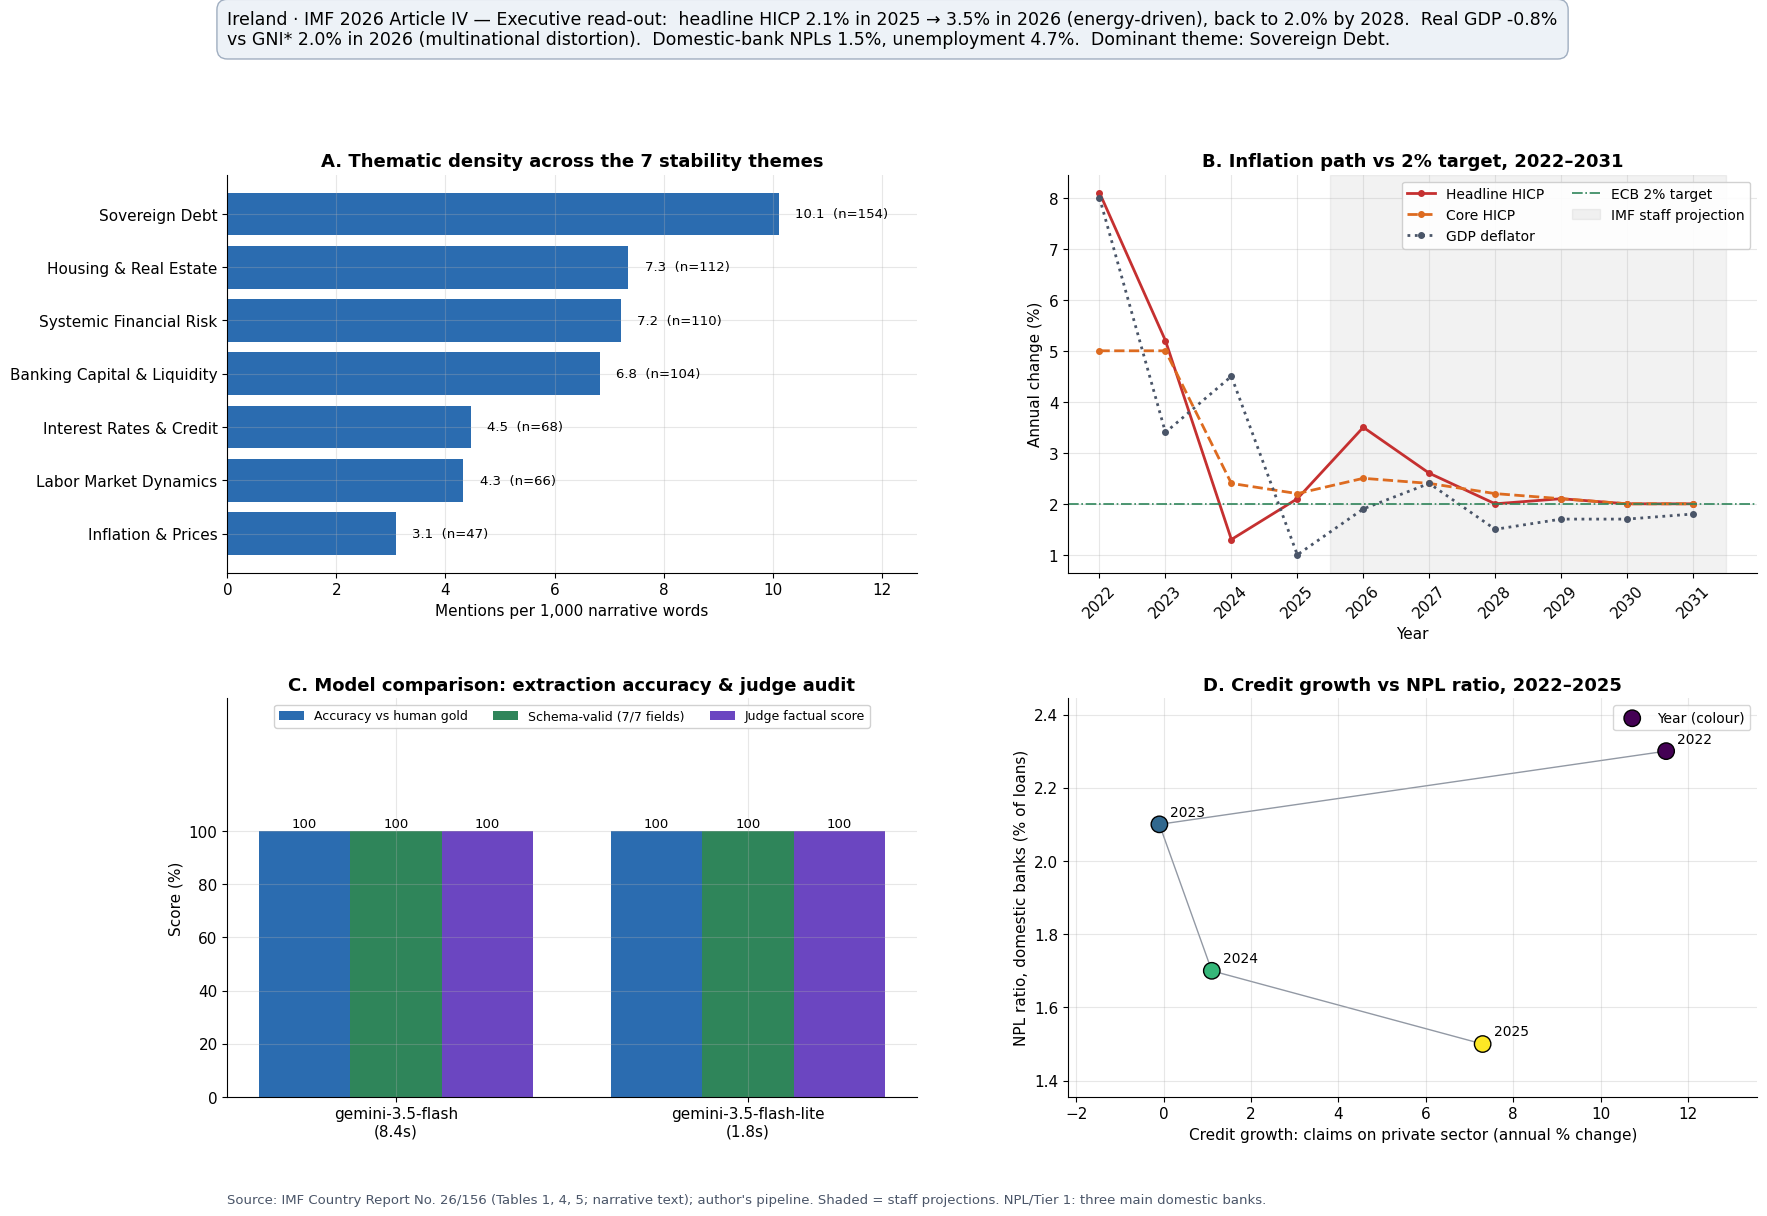

saved outputs/figures/dashboard.png


In [39]:
plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
                     "legend.fontsize": 10, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
C = dict(blue="#2b6cb0", orange="#dd6b20", green="#2f855a", red="#c53030", grey="#4a5568", purple="#6b46c1")

hicp   = get_series("T1", "Inflation (HICP)")
core   = get_series("T1", "Inflation (HICP, core)")
defl   = get_series("T1", "GDP deflator")
gdp    = get_series("T1", "Real GDP")
gni    = get_series("T1", "Real GNI* (growth rate)")
unemp  = get_series("T1", "Unemployment rate (percent)")
npl    = get_series("T5", "NPL ratio")
ct1    = get_series("T5", "CT1 ratio")
credit = get_series("T4", "Claims on private sector", occurrence=2)   # 2nd block of Table 4 = annual % change

def val(s, year):
    return None if s is None or year not in s.index else float(s[year])
def fmt(v, suffix="%"): return "n/a" if v is None else f"{v:.1f}{suffix}"

def panel_themes(ax):
    d = theme_df.sort_values("per_1000_words")
    bars = ax.barh(d.index, d.per_1000_words, color=C["blue"])
    for b, (occ, dens) in zip(bars, zip(d.occurrences, d.per_1000_words)):
        ax.text(b.get_width() + 0.3, b.get_y() + b.get_height() / 2, f"{dens:.1f}  (n={occ})", va="center", fontsize=9.5)
    ax.set_xlabel("Mentions per 1,000 narrative words"); ax.set_title("A. Thematic density across the 7 stability themes")
    ax.set_xlim(0, d.per_1000_words.max() * 1.25)

def panel_inflation(ax):
    for s, lab, col, ls in ((hicp, "Headline HICP", C["red"], "-"), (core, "Core HICP", C["orange"], "--"), (defl, "GDP deflator", C["grey"], ":")):
        if s is not None: ax.plot(s.index, s.values, marker="o", ms=4, lw=2, color=col, ls=ls, label=lab)
    ax.axhline(2.0, color=C["green"], lw=1.2, ls="-.", label="ECB 2% target")
    ax.axvspan(REPORT_YEAR - 0.5, YEAR_COLS[-1] + 0.5, color="grey", alpha=0.10, label="IMF staff projection")
    ax.set_ylabel("Annual change (%)"); ax.set_xlabel("Year"); ax.set_title("B. Inflation path vs 2% target, 2022–2031")
    ax.legend(loc="upper right", ncol=2, framealpha=0.9); ax.set_xticks(range(2022, 2032, 1)); ax.tick_params(axis="x", labelrotation=45)

def panel_models(ax):
    labels, series = [], {"Accuracy vs human gold": [], "Schema-valid (7/7 fields)": [], "Judge factual score": []}
    for lab, run in EXTRACTION_RUNS.items():
        labels.append(f"{run['model']}\n({run['latency_s']:.1f}s)")
        series["Accuracy vs human gold"].append(100 * run["gold_accuracy"])
        series["Schema-valid (7/7 fields)"].append(100 * float(run["schema_valid"]))
        series["Judge factual score"].append(run["audit"]["factual_alignment"] / 5 * 100)
    x, w = np.arange(len(labels)), 0.26
    for i, ((name, vals), col) in enumerate(zip(series.items(), (C["blue"], C["green"], C["purple"]))):
        bars = ax.bar(x + (i - 1) * w, vals, w, label=name, color=col)
        for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.0f}", ha="center", fontsize=9.5)
    ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0, 150); ax.set_yticks(range(0, 101, 20)); ax.set_ylabel("Score (%)")
    ax.set_title("C. Model comparison: extraction accuracy & judge audit"); ax.legend(loc="upper center", ncol=3, fontsize=9, framealpha=0.9)

def panel_scatter(ax):
    yrs = [y for y in (2022, 2023, 2024, 2025) if credit is not None and npl is not None and y in credit.index and y in npl.index]
    if not yrs:
        ax.text(0.5, 0.5, "credit / NPL series not available", ha="center", transform=ax.transAxes); return
    xs, ys = [credit[y] for y in yrs], [npl[y] for y in yrs]
    ax.plot(xs, ys, color=C["grey"], lw=1, alpha=0.6, zorder=1)
    sc = ax.scatter(xs, ys, c=yrs, cmap="viridis", s=140, zorder=2, edgecolor="k", label="Year (colour)")
    for x, y, yr in zip(xs, ys, yrs): ax.annotate(str(yr), (x, y), textcoords="offset points", xytext=(8, 6), fontsize=10)
    ax.set_xlabel("Credit growth: claims on private sector (annual % change)"); ax.set_ylabel("NPL ratio, domestic banks (% of loans)")
    ax.set_title("D. Credit growth vs NPL ratio, 2022–2025"); ax.legend(loc="upper right")
    ax.margins(0.18)

def banner_text():
    return (f"{COUNTRY} · IMF {REPORT_YEAR} Article IV — Executive read-out:  headline HICP {fmt(val(hicp, LAST_ACTUAL_YEAR))} in {LAST_ACTUAL_YEAR} → "
            f"{fmt(val(hicp, REPORT_YEAR))} in {REPORT_YEAR} (energy-driven), back to {fmt(val(hicp, 2028))} by 2028.  Real GDP {fmt(val(gdp, REPORT_YEAR))} vs GNI* {fmt(val(gni, REPORT_YEAR))} in {REPORT_YEAR}"
            f" (multinational distortion).  Domestic-bank NPLs {fmt(val(npl, LAST_ACTUAL_YEAR))}, unemployment {fmt(val(unemp, LAST_ACTUAL_YEAR))}.  "
            f"Dominant theme: {theme_df.index[0]}.")

def build_dashboard(path):
    fig = plt.figure(figsize=(17, 12.5))
    gs = fig.add_gridspec(3, 2, height_ratios=[0.3, 3, 3], hspace=0.45, wspace=0.22, left=0.07, right=0.97, top=0.97, bottom=0.10)
    axt = fig.add_subplot(gs[0, :]); axt.axis("off")
    import textwrap
    axt.text(0.0, 0.5, "\n".join(textwrap.wrap(banner_text(), 150)), fontsize=12.5, va="center", ha="left", transform=axt.transAxes,
             bbox=dict(boxstyle="round,pad=0.6", fc="#edf2f7", ec="#a0aec0"))
    panel_themes(fig.add_subplot(gs[1, 0])); panel_inflation(fig.add_subplot(gs[1, 1]))
    panel_models(fig.add_subplot(gs[2, 0])); panel_scatter(fig.add_subplot(gs[2, 1]))
    fig.text(0.07, 0.015, f"Source: IMF Country Report No. 26/156 (Tables 1, 4, 5; narrative text); author's pipeline. Shaded = staff projections. NPL/Tier 1: three main domestic banks.", fontsize=9.5, color=C["grey"])
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white"); plt.show(); plt.close(fig)

build_dashboard(FIG_DIR / "dashboard.png")
print("saved", FIG_DIR / "dashboard.png")

### 11b. Supporting figures for the report (each saved at dpi = 300)

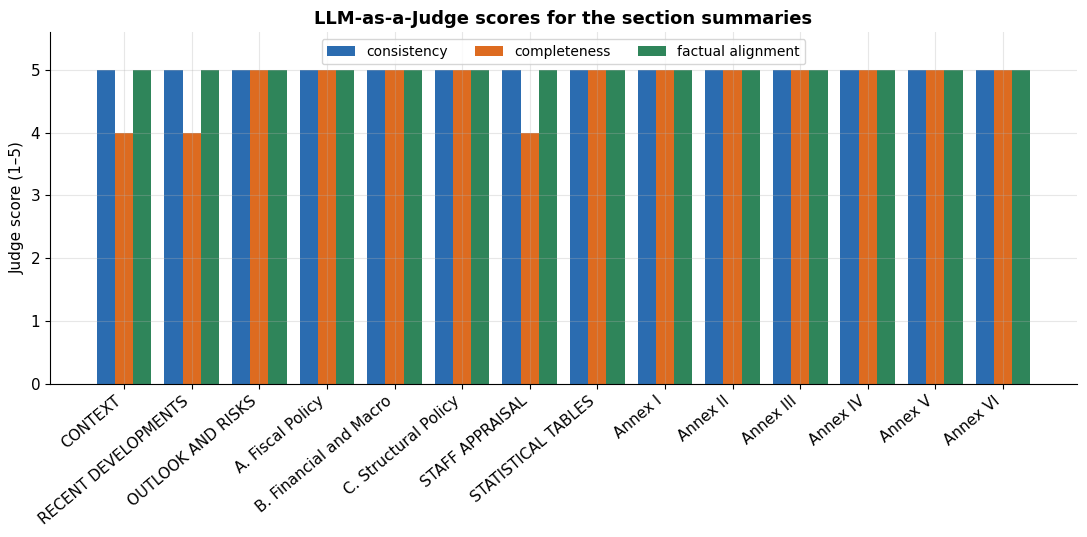

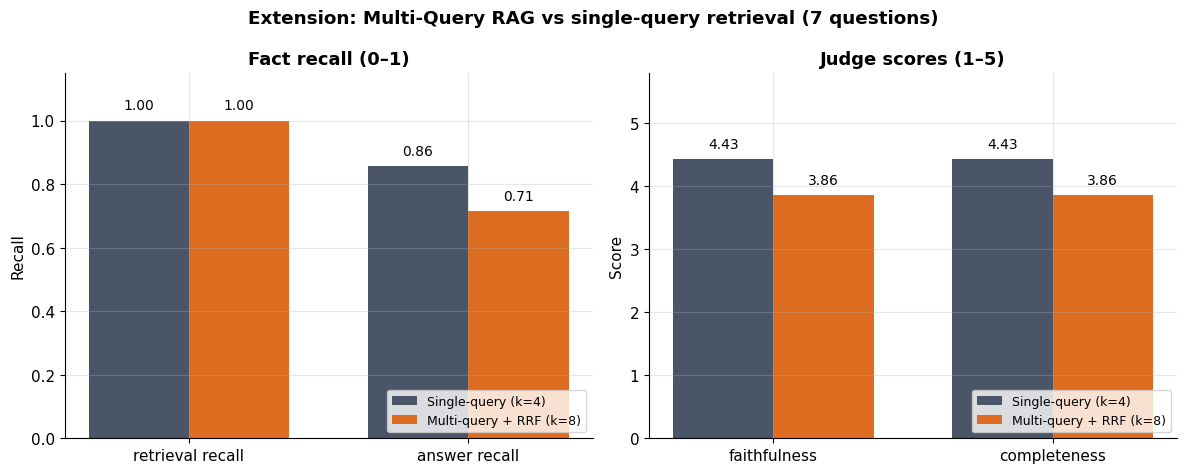

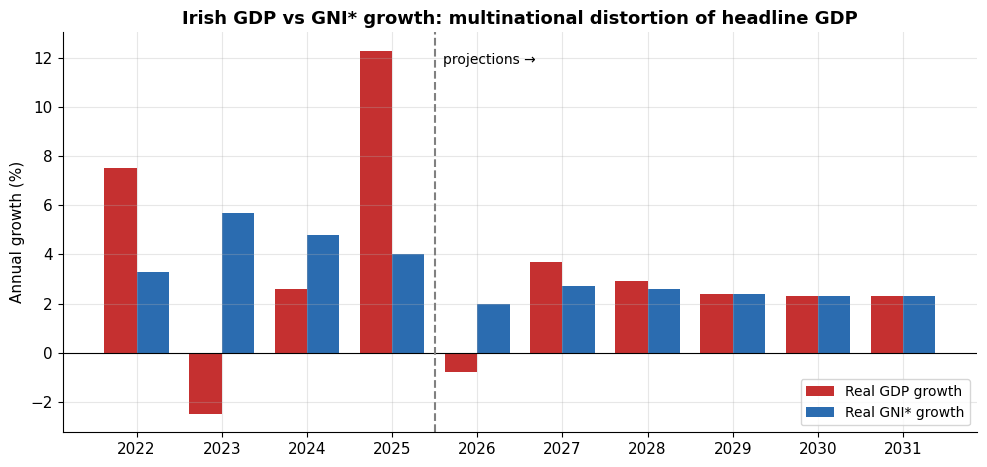

In [40]:
def fig_judge_by_section(path):
    d = pd.DataFrame({n: r["judge"] for n, r in SECTION_SUMMARIES.items()}).T[["consistency", "completeness", "factual_alignment"]].astype(float)
    d.index = [i.split(".")[0] if i.startswith("Annex") else i for i in d.index]
    fig, ax = plt.subplots(figsize=(11, 5.5)); x = np.arange(len(d)); w = 0.27
    for i, (col, cc) in enumerate(zip(d.columns, (C["blue"], C["orange"], C["green"]))):
        ax.bar(x + (i - 1) * w, d[col], w, label=col.replace("_", " "), color=cc)
    ax.set_xticks(x); ax.set_xticklabels([t[:22] for t in d.index], rotation=40, ha="right"); ax.set_ylim(0, 5.6); ax.set_yticks(range(0, 6))
    ax.set_ylabel("Judge score (1–5)"); ax.set_title("LLM-as-a-Judge scores for the section summaries"); ax.legend(ncol=3, loc="upper center")
    fig.tight_layout(); fig.savefig(path, dpi=300, facecolor="white"); plt.show(); plt.close(fig)

def fig_multiquery(path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    m = ["retrieval_recall", "answer_recall"]; x = np.arange(len(m)); w = 0.36
    for ax, mets, ttl, yl, ylim in ((axes[0], m, "Fact recall (0–1)", "Recall", 1.15), (axes[1], ["faithfulness", "completeness"], "Judge scores (1–5)", "Score", 5.8)):
        x = np.arange(len(mets))
        for i, (col, lab, cc) in enumerate((("single_query", "Single-query (k=4)", C["grey"]), ("multi_query", "Multi-query + RRF (k=8)", C["orange"]))):
            vals = [cmp_df.loc[k, col] for k in mets]
            bars = ax.bar(x + (i - 0.5) * w, vals, w, label=lab, color=cc)
            for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v + 0.03 * ylim, f"{v:.2f}", ha="center", fontsize=10)
        ax.set_xticks(x); ax.set_xticklabels([k.replace("_", " ") for k in mets]); ax.set_ylim(0, ylim); ax.set_ylabel(yl); ax.set_title(ttl); ax.legend(loc="lower right", fontsize=9)
    fig.suptitle(f"Extension: Multi-Query RAG vs single-query retrieval ({len(mq_df)} questions)", fontweight="bold"); fig.tight_layout()
    fig.savefig(path, dpi=300, facecolor="white"); plt.show(); plt.close(fig)

def fig_gdp_gni(path):
    if gdp is None or gni is None: return
    fig, ax = plt.subplots(figsize=(10, 4.8)); idx = np.arange(len(gdp)); w = 0.38
    ax.bar(idx - w / 2, gdp.values, w, color=C["red"], label="Real GDP growth"); ax.bar(idx + w / 2, gni.reindex(gdp.index).values, w, color=C["blue"], label="Real GNI* growth")
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(idx); ax.set_xticklabels(gdp.index); ax.set_ylabel("Annual growth (%)")
    ax.axvline(list(gdp.index).index(REPORT_YEAR) - 0.5, color="grey", ls="--"); ax.text(list(gdp.index).index(REPORT_YEAR) - 0.4, ax.get_ylim()[1] * 0.9, "projections →", fontsize=10)
    ax.set_title("Irish GDP vs GNI* growth: multinational distortion of headline GDP"); ax.legend(loc="lower right")
    fig.tight_layout(); fig.savefig(path, dpi=300, facecolor="white"); plt.show(); plt.close(fig)

fig_judge_by_section(FIG_DIR / "judge_scores_sections.png"); fig_multiquery(FIG_DIR / "multiquery_vs_single.png"); fig_gdp_gni(FIG_DIR / "gdp_vs_gni.png")

## 12. Run manifest and file inventory
Everything quoted in the written report is produced above: `indicators.json`, `indicator_audit_trail.json`, `extraction_comparison.json`, `thematic_counts.json`, `qualitative_insights.json`, `summaries.json`, `prompt_ab.json`, `rag_eval_single_query.json`, `extension_multiquery.json`, `indicators_long.csv`, `trend_series.json` and `figures/*.png`.

In [41]:
fresh = [l for l in LLM_LOG if not l[3]]; cached = [l for l in LLM_LOG if l[3]]
manifest = dict(country=COUNTRY, report="IMF Country Report No. 26/156", models=dict(generator=GEN_MODEL, alt=ALT_MODEL, judge=JUDGE_MODEL),
                embedding_model=EMBED_MODEL, chunk_tokens=CHUNK_TOKENS, chunk_overlap=CHUNK_OVERLAP, n_chunks=len(CHUNKS),
                llm_calls=dict(total=len(LLM_LOG), fresh=len(fresh), from_cache=len(cached),
                               by_model={m: sum(1 for l in LLM_LOG if l[1] == m) for m in sorted({l[1] for l in LLM_LOG})},
                               mean_latency_s=round(float(np.mean([l[2] for l in LLM_LOG])), 2) if LLM_LOG else None),
                fallbacks=PRIMARY["flags"] and list(PRIMARY["flags"]), gold_accuracy={k: v["gold_accuracy"] for k, v in EXTRACTION_RUNS.items()})
save_json(manifest, "run_manifest.json")
print(json.dumps(manifest, indent=1))
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file() and "llm_cache" not in p.parts: print(f"{p.relative_to(OUT_DIR)!s:45s} {p.stat().st_size/1024:8.1f} KB")

{
 "country": "Ireland",
 "report": "IMF Country Report No. 26/156",
 "models": {
  "generator": "gemini-3.5-flash",
  "alt": "gemini-3.5-flash-lite",
  "judge": "gemini-3.5-flash"
 },
 "embedding_model": "sentence-transformers/multi-qa-distilbert-cos-v1",
 "chunk_tokens": 400,
 "chunk_overlap": 50,
 "n_chunks": 95,
 "llm_calls": {
  "total": 89,
  "fresh": 0,
  "from_cache": 89,
  "by_model": {
   "gemini-3.5-flash": 87,
   "gemini-3.5-flash-lite": 2
  },
  "mean_latency_s": 6.3
 },
 "fallbacks": [
  "central_bank_policy_rate_pct"
 ],
 "gold_accuracy": {
  "GEN": 1.0,
  "ALT": 1.0
 }
}
extension_multiquery.json                          8.0 KB
extraction_comparison.json                         8.6 KB
figures/dashboard.png                            848.1 KB
figures/gdp_vs_gni.png                           114.2 KB
figures/judge_scores_sections.png                286.6 KB
figures/multiquery_vs_single.png                 151.6 KB
indicator_audit_trail.json                         1.5 KB
